# AURUM MARKET

breve descripcion

## Imports y variables globales

Seguimos estrucutura de los proyectos de clase, las funciones las mantenemos en la carpeta `src/` para tener un notebook claro


In [ ]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from dotenv import load_dotenv

current_directory = Path.cwd().resolve()
# buscamos directorio raíz 
project_root = next(
    candidate
    for candidate in (current_directory, *current_directory.parents)
    if (candidate / "pyproject.toml").exists()
)
# añadimos 'src' a las rutas de búsqueda
sys.path.insert(0, str(project_root / "src"))


In [ ]:
from ecommerce import (
    ESCI_GAINS,
    ESCI_LABEL_NAMES,
    load_esci_sample,
)

In [2]:
# cargamos .env
load_dotenv(project_root / ".env", override=False)
# tema blanco para los gráficos
pio.templates.default = "plotly_white"

In [ ]:
# cargamos productos y relevancias preprocesadas
sample = load_esci_sample()
products = sample.products.copy()
judgments = sample.judgments.copy()
# cargamos consultas
development_queries = pd.read_csv(
    project_root / "data/consultas_desarrollo.csv"
)


In [ ]:
print(f"Productos: {len(products):,}")
print(f"Consultas: {len(development_queries):,}")
print(f"Juicios consulta-producto: {len(judgments):,}")

Productos: 1,500
Consultas originales: 8
Paráfrasis de estrés: 8
Juicios consulta-producto: 248


In [ ]:
# visualizamos la variedad de relevancias con respecto a su etiqueta ESCI
label_summary = (
    judgments["esci_label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="pairs")
)
label_summary["meaning"] = label_summary["label"].map(
    ESCI_LABEL_NAMES
)
label_summary


,label,pairs,meaning
0,E,121,Exact
1,S,77,Substitute
2,I,46,Irrelevant
3,C,4,Complement


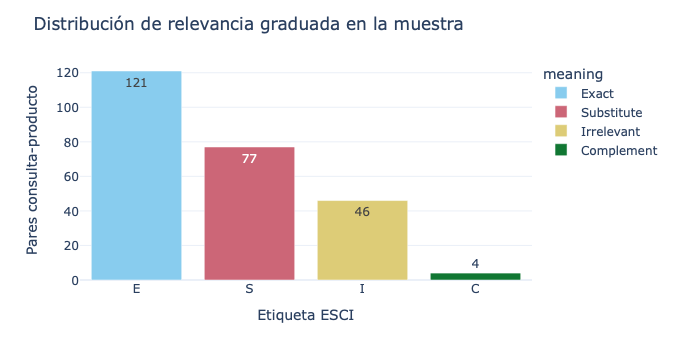

In [ ]:
# misma comparación pero más visual en un gráfico
label_figure = px.bar(
    label_summary,
    x="label",
    y="pairs",
    color="meaning",
    text="pairs",
    color_discrete_sequence=px.colors.qualitative.Safe,
)
label_figure.update_layout(
    title="Distribución de relevancia graduada en la muestra",
    xaxis_title="Etiqueta ESCI",
    yaxis_title="Pares consulta-producto",
)
label_figure.show()

In [ ]:
# visualizamos un producto de ejemplo
product_example = products.iloc[0]

display(product_example[["title", "brand", "color", "text"]])

title    bonmedico Almohada Ergonómica para el Cuello H...
brand                                            bonmedico
color                                                 Azul
text     bonmedico Almohada Ergonómica para el Cuello H...
Name: 336, dtype: object

In [11]:
print(product_example["searchable_text"][:1_200])

bonmedico Almohada Ergonómica para el Cuello Hecha de Espuma de Memoria, Almohada de Viaje y Almohada para el Cuello, Almohada de Viaje (Azul).. Marca: bonmedico. Color: Azul. bonmedico Almohada Ergonómica para el Cuello Hecha de Espuma de Memoria, Almohada de Viaje y Almohada para el Cuello, Almohada de Viaje (Azul).. Marca: bonmedico. Color: Azul. Características: &#10004 UNIVERSAL: La almohada para el cuello es muy versátil y es adecuada tanto para hombres como para mujeres. &#10004 TAMAÑO: Las medidas del producto: 28cm x 32cm x 11cm. &#10004 ALTA TECNOLOGÍA: El cojín en forma de media luna consiste en una capa de gel refrigerante y espuma de memoria viscoelástica comprimida. La espuma de memoria vuelve a su forma original después de su uso. &#10004 CÓMODO: La almohada para el cuello tiene una funda de algodón transpirable, con cremallera y desmontable. &#10004 HIGIENE: La funda de almohada se puede lavar a máquina a 30°C. Composición: Cojín: 100% espuma de poliuretano 45D con capa